In [20]:
from pathlib import Path

print(Path.cwd())

C:\Users\ADMIN


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [27]:
from pathlib import Path

PROJeCT_DIR = Path(r'C:\Users\ADMIN\Desktop\Data\electricity-demand-forecasting')

data_path = PROJeCT_DIR / 'data' / 'PJME_hourly.csv'

print(data_path)
print(data_path.exists())

C:\Users\ADMIN\Desktop\Data\electricity-demand-forecasting\data\PJME_hourly.csv
True


In [2]:
from pathlib import Path

data_path = Path('Desktop/Data/electricity-demand-forecasting/data/PJME_hourly.csv')
data = pd.read_csv(data_path)

PJ = pd.DataFrame(data)
PJ['Datetime'] = pd.to_datetime(PJ['Datetime'])
PJ.set_index('Datetime', inplace=True)
PJ.sort_index(inplace=True)
PJ.head()

,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [3]:
# Time features
PJ['hour'] = PJ.index.hour
PJ['dayofweek'] = PJ.index.dayofweek
PJ['month'] = PJ.index.month
PJ['dayofyear'] = PJ.index.day
PJ['weekofyear'] = PJ.index.isocalendar().week.astype(int)
PJ['year'] = PJ.index.year
PJ['is_weekend'] = PJ['dayofweek'].isin([5,6]).astype(int)

In [4]:
#Lag features

PJ['lag_1'] = PJ['PJME_MW'].shift(1)
PJ['lag_24'] = PJ['PJME_MW'].shift(24)
PJ['lag_48'] = PJ['PJME_MW'].shift(48)
PJ['lag_168'] = PJ['PJME_MW'].shift(168)

In [5]:
PJ['hour_sin'] = np.sin(2*np.pi * PJ['hour']/24)
PJ['hour_cos'] = np.cos(2*np.pi * PJ['hour']/24)

PJ['month_sin'] = np.sin(2*np.pi * PJ['month']/12)
PJ['month_cos'] = np.cos(2*np.pi * PJ['month']/12)

In [6]:
#Rolling statistics

PJ['rolling_mean_24'] = PJ['PJME_MW'].shift(1).rolling(window=24).mean()
PJ['rolling_std_24'] = PJ['PJME_MW'].shift(1).rolling(window=24).std()

PJ.dropna(inplace=True)

In [7]:
Features = ['hour', 'dayofweek', 'month', 'dayofyear', 'weekofyear', 'lag_1', 'lag_24', 'lag_48', 'lag_168','hour_sin','hour_cos', 'month_sin', 'month_cos', 'rolling_mean_24', 'rolling_std_24']

Target = 'PJME_MW'


<Axes: xlabel='Datetime'>

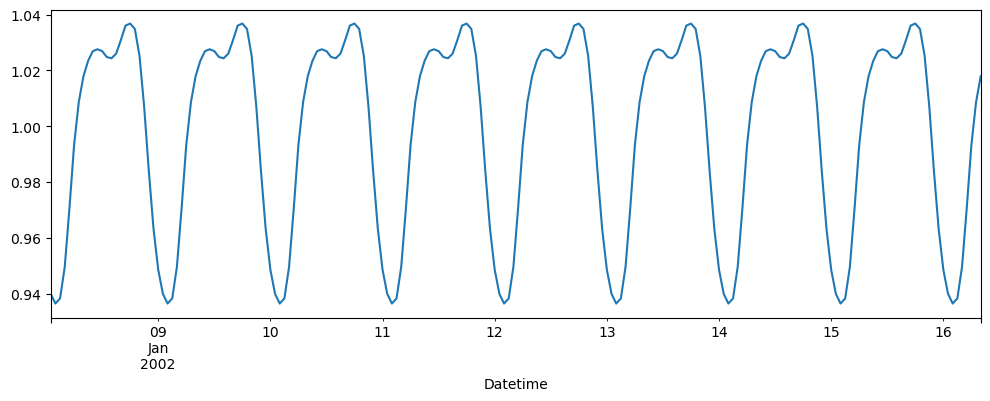

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

sd = seasonal_decompose(PJ['PJME_MW'], model='multiplicative', period=24)
sd.seasonal[:200].plot(figsize=(12,4))

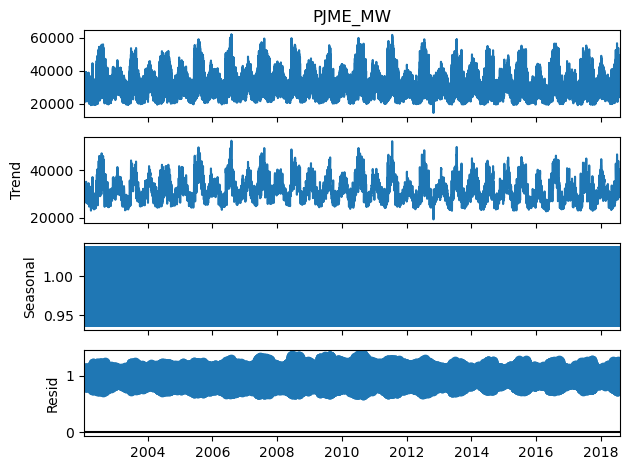

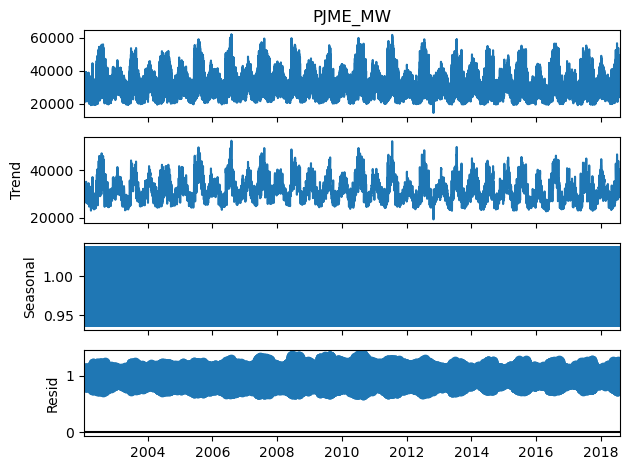

In [9]:
sd.plot()

In [ ]:
#Interpretation

# 1. Observed Series

# The data shows strong fluctuations over time.
# electricity demands varies between roughly 20,000 MW to 60,000 MW
# This means electricity consumption changes regularly with time.

# 2. Trend (after removing seasonality)

# The trend is relatively stable but slowly varying over the years. some periods show increased electricity demand.
# This means power consumption remains generally consistent over the years with moderate long-term variation.

# 3. Seasonal

# There is strong repetitive daily behavior in electricity usage. 
# Higher during active daytime hours and lower during nightime

#4. Resid

# Residuals spikes varies around a constant seasonal. This maybe holidays, excessive use of electricity during a particular daytime


In [8]:
from statsmodels.tsa.stattools import adfuller

sample = PJ['PJME_MW'].iloc[:4000]
check_stationarity = adfuller(sample)

print('ADF Statistic:', check_stationarity[0])
print('P-Value:', check_stationarity[1])
print('Critical values:', check_stationarity[4])

ADF Statistic: -7.775791448490148
P-Value: 8.676828031430775e-12
Critical values: {'1%': -3.4319978298121763, '5%': -2.862268121070097, '10%': -2.5671575868492806}


In [ ]:
# p-value is far less than 0.05
# ADF statistic is more negative than all critical values
# The series is stationary

In [9]:
PJ_small = PJ.iloc[:10000]

split = int(len(PJ_small)*0.8)
train = PJ_small.iloc[:split]
test = PJ_small.iloc[split:]

x_train = train[Features]
x_test = test[Features]

y_train = train[Target]
y_test = test[Target]

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    y_train,
    exog=x_train,
    order=(2,0,2),
    seasonal_order=(1,1,1,24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit()
print(result.summary())

C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                      SARIMAX Results                                       
Dep. Variable:                              PJME_MW   No. Observations:                 8000
Model:             SARIMAX(2, 0, 2)x(1, 1, [1], 24)   Log Likelihood              -58623.677
Date:                              Mon, 08 Jun 2026   AIC                         117291.355
Time:                                      13:40:54   BIC                         117444.933
Sample:                                           0   HQIC                        117343.939
                                             - 8000                                         
Covariance Type:                                opg                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
hour               19.2585      5.738      3.356      0.001       8.012      30.505
dayo

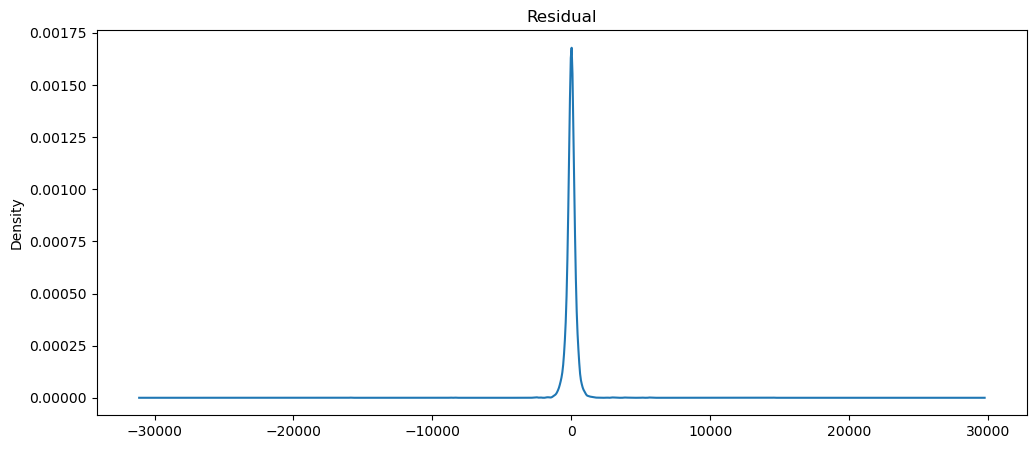

       lb_stat     lb_pvalue
24  300.449383  1.361528e-49
48  434.964824  8.813171e-64
72  480.872430  9.302692e-62


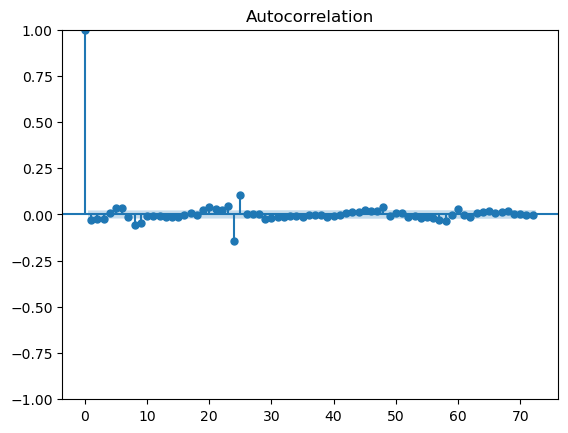

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ReSIDUAL DIAGNOSTIC

residual = result.resid

plt.figure(figsize=(12,5))
residual.plot(kind='kde')
plt.title('Residual')
plt.show()

# ACF 
plot_acf(residual, lags=72)
plt.show


#Ljung-Box Test

from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(residual, lags=[24,48,72], return_df=True)
print(lb)

C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


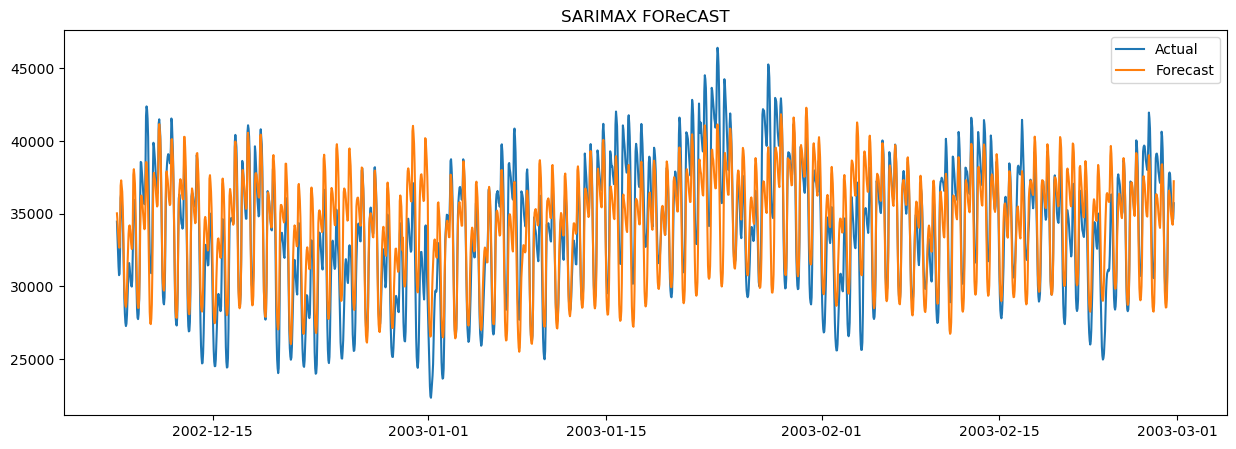

In [13]:
# VALIDATION

forecast = result.forecast(steps=len(test), exog=x_test)

plt.figure(figsize=(15,5))

plt.plot(test.index, test['PJME_MW'], label='Actual')
plt.plot(test.index, forecast, label='Forecast')

plt.legend()
plt.title('SARIMAX FOReCAST')
plt.show()


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, forecast)
rmse = mean_squared_error(y_test, forecast)
r2_score = r2_score(y_test, forecast)

print('mean absolute error:{:.2f}'.format(mae))
print('mean squared error:{:.2f}'.format(rmse))
print('r2_score:{:.3f}'.format(r2_score))

mean absolute error:2005.62
mean squared error:6162913.63
r2_score:0.680


In [17]:
RMSe = np.sqrt(rmse)
print(RMSe)

2482.5216274593217


In [18]:
#Comparison

# Histgradintboosting was better able to model th complex and nonlinear relationships between the predictors and electricity demand
# while SARIMAX is contrained by its linear assumptions and specified autorgressive structure, which may not fully capture the
# dynamics of electricity demand.

In [19]:
#autocorrlation

# pvalue is significantly below 0.05, indicating that there is still autocorrelation in residual. this imply sarimax did not 
# fully capture dependencies in the electricity demand data. 

In [ ]:
# this is not a fair comparison due to the computational complexity and long training time of SARIMAX. the model was estimated
# using a sample of 10000 observations. hist being computationally more efficient, was traind on the full dataset. 